# Swing Rate by Zone — Pull Air% Analysis
Engineers inner-half and outer-half swing rates per batter (fit to each
handedness) and correlates with Pull% on air balls.

**Sections**
1. Imports & config
2. Load all pitches (raw Statcast)
3. Engineer zone swing rates
4. Build batter-level leaderboard
5. Correlations with Pull% (Air Only)
6. Stickiness of zone swing rates
7. Regression: zone swing rates + swing metrics → Pull% (Air Only)


## 1. Imports & Config

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from scipy.stats import spearmanr, pearsonr
from sklearn.linear_model import RidgeCV
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import cross_val_score
from sklearn.pipeline import Pipeline

pd.set_option("display.max_columns", 60)
pd.set_option("display.float_format", "{:.3f}".format)

MIN_BBE       = 25    # minimum contact events for Pull% (Air Only)
MIN_PITCHES   = 50    # minimum pitches seen for swing rate metrics

# Swing decisions — all values in 'description' that count as a swing
SWING_DESCS = {
    "swinging_strike",
    "swinging_strike_blocked",
    "foul",
    "foul_tip",
    "foul_bunt",
    "missed_bunt",
    "hit_into_play",
    "hit_into_play_no_out",
    "hit_into_play_score",
}

print("Imports OK")


Imports OK


## 2. Load All Pitches

In [2]:
raw_2024 = pd.read_parquet(Path("statcast_2024.parquet"))
raw_2025 = pd.read_parquet(Path("statcast_2025.parquet"))

print(f"2024 raw: {len(raw_2024):,}")
print(f"2025 raw: {len(raw_2025):,}")

# Filter to pitches with plate location and batter info
def filter_pitches(df):
    mask = (
        df["plate_x"].notna() &
        df["plate_z"].notna() &
        df["sz_top"].notna() &
        df["sz_bot"].notna() &
        df["stand"].notna() &
        df["batter"].notna() &
        df["description"].notna()
    )
    return df[mask].copy().reset_index(drop=True)

pitches_2024 = filter_pitches(raw_2024)
pitches_2025 = filter_pitches(raw_2025)
pitches_all  = pd.concat([pitches_2024, pitches_2025], ignore_index=True)

print(f"\n2024 pitches with location: {len(pitches_2024):,}")
print(f"2025 pitches with location: {len(pitches_2025):,}")
print(f"Combined: {len(pitches_all):,}")


2024 raw: 731,904
2025 raw: 734,846

2024 pitches with location: 721,412
2025 pitches with location: 724,879
Combined: 1,446,291


## 3. Engineer Zone Swing Rates
`plate_x` is from the catcher's POV — negative = arm side of RHH (inner half),
positive = glove side. Flip for LHH so inner-half is always pull-side.

The inner/outer boundary is fit separately per handedness using the median
`plate_x` of all called strikes, which approximates the centre of the zone.


In [3]:
# ── Swing flag
pitches_all["is_swing"] = pitches_all["description"].isin(SWING_DESCS).astype(int)
pitches_2024["is_swing"] = pitches_2024["description"].isin(SWING_DESCS).astype(int)
pitches_2025["is_swing"] = pitches_2025["description"].isin(SWING_DESCS).astype(int)

# ── Plate x normalised: inner-half (pull-side) = negative for both sides
# Statcast: negative plate_x = catcher's left = RHH inner half
# Flip for LHH so inner = negative for both
for df in [pitches_all, pitches_2024, pitches_2025]:
    df["plate_x_norm"] = np.where(
        df["stand"] == "R",
        df["plate_x"],
        -df["plate_x"],
    )

# ── Find inner/outer boundary per handedness
# Use median plate_x of called strikes as zone centre proxy
boundaries = {}
for side in ["R", "L"]:
    called = pitches_all[
        (pitches_all["stand"] == side) &
        (pitches_all["description"] == "called_strike")
    ]["plate_x_norm"]
    boundaries[side] = float(called.median())
    print(f"{side}HH zone centre (plate_x_norm median of called strikes): "
          f"{boundaries[side]:.3f} ft")

# Single boundary: use average across both sides
INNER_OUTER_BOUNDARY = np.mean(list(boundaries.values()))
print(f"\nUsing boundary: {INNER_OUTER_BOUNDARY:.3f} ft  "
      f"(negative = inner/pull-side, positive = outer/oppo-side)")

# ── Zone flag: inner = plate_x_norm <= boundary, outer = plate_x_norm > boundary
for df in [pitches_all, pitches_2024, pitches_2025]:
    df["is_inner"] = (df["plate_x_norm"] <= INNER_OUTER_BOUNDARY).astype(int)
    df["is_outer"] = (df["plate_x_norm"] >  INNER_OUTER_BOUNDARY).astype(int)


RHH zone centre (plate_x_norm median of called strikes): 0.197 ft
LHH zone centre (plate_x_norm median of called strikes): 0.192 ft

Using boundary: 0.195 ft  (negative = inner/pull-side, positive = outer/oppo-side)


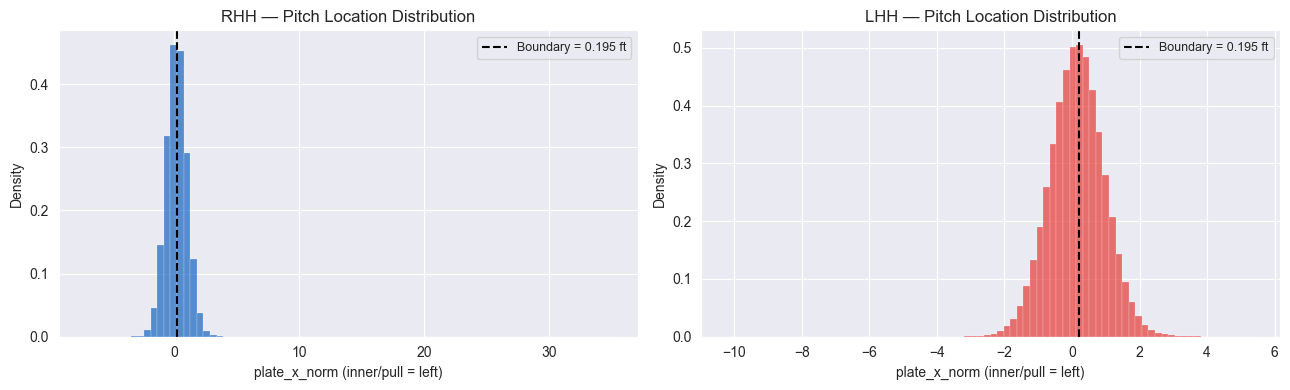

In [4]:
# ── Visualise zone split
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

for ax, side, color in zip(axes, ["R", "L"], ["#1565C0", "#E53935"]):
    sub = pitches_all[pitches_all["stand"] == side]["plate_x_norm"]
    ax.hist(sub, bins=80, color=color, alpha=0.7,
            edgecolor="white", linewidth=0.2, density=True)
    ax.axvline(INNER_OUTER_BOUNDARY, color="black", linewidth=1.5,
               linestyle="--", label=f"Boundary = {INNER_OUTER_BOUNDARY:.3f} ft")
    ax.set_xlabel("plate_x_norm (inner/pull = left)")
    ax.set_ylabel("Density")
    ax.set_title(f"{side}HH — Pitch Location Distribution")
    ax.legend(fontsize=9)

plt.tight_layout()
plt.show()


## 4. Build Batter-Level Leaderboard

In [5]:
def compute_swing_rates(pitches: pd.DataFrame, min_pitches: int) -> pd.DataFrame:
    """
    Per-batter swing rates on inner-half and outer-half pitches.
    """
    agg = (
        pitches.groupby("batter")
        .apply(lambda g: pd.Series({
            "n_pitches":       len(g),
            "n_inner":         g["is_inner"].sum(),
            "n_outer":         g["is_outer"].sum(),
            "swings_inner":    (g["is_inner"] * g["is_swing"]).sum(),
            "swings_outer":    (g["is_outer"] * g["is_swing"]).sum(),
            "stand":           g["stand"].iloc[0],
        }))
        .reset_index()
    )
    agg["swing_rate_inner"] = agg["swings_inner"] / agg["n_inner"].clip(lower=1)
    agg["swing_rate_outer"] = agg["swings_outer"] / agg["n_outer"].clip(lower=1)
    agg["inner_outer_diff"] = agg["swing_rate_inner"] - agg["swing_rate_outer"]
    return agg[agg["n_pitches"] >= min_pitches].reset_index(drop=True)


sr_all  = compute_swing_rates(pitches_all,  MIN_PITCHES)
sr_2024 = compute_swing_rates(pitches_2024, MIN_PITCHES)
sr_2025 = compute_swing_rates(pitches_2025, MIN_PITCHES)

print(f"Batters with ≥{MIN_PITCHES} pitches (combined): {len(sr_all)}")
print(f"\nSwing rate summary (combined):")
print(sr_all[["swing_rate_inner", "swing_rate_outer", "inner_outer_diff"]].describe().round(3))


Batters with ≥50 pitches (combined): 740

Swing rate summary (combined):
       swing_rate_inner  swing_rate_outer  inner_outer_diff
count           740.000           740.000           740.000
mean              0.553             0.412             0.141
std               0.066             0.066             0.079
min               0.280             0.182            -0.224
25%               0.511             0.366             0.093
50%               0.550             0.411             0.141
75%               0.593             0.456             0.192
max               0.806             0.692             0.502


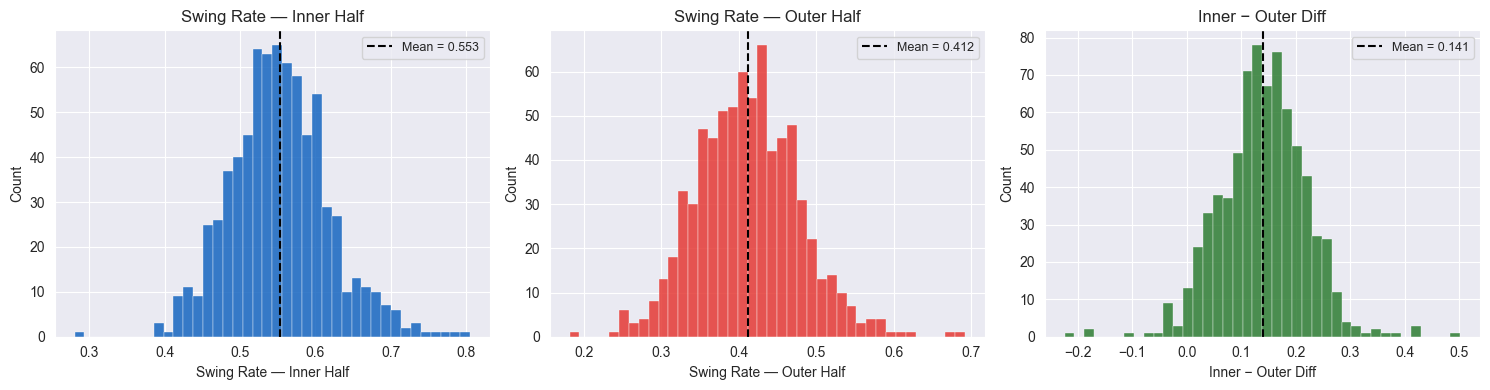


RHH (n=424):
  inner swing rate: 0.560
  outer swing rate: 0.418
  inner−outer diff: 0.142

LHH (n=316):
  inner swing rate: 0.543
  outer swing rate: 0.404
  inner−outer diff: 0.139


In [6]:
# ── Distribution of swing rates
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, col, label, color in zip(axes,
    ["swing_rate_inner", "swing_rate_outer", "inner_outer_diff"],
    ["Swing Rate — Inner Half", "Swing Rate — Outer Half", "Inner − Outer Diff"],
    ["#1565C0", "#E53935", "#2E7D32"],
):
    ax.hist(sr_all[col], bins=40, color=color, alpha=0.85,
            edgecolor="white", linewidth=0.3)
    ax.axvline(sr_all[col].mean(), color="black", linewidth=1.5, linestyle="--",
               label=f"Mean = {sr_all[col].mean():.3f}")
    ax.set_xlabel(label)
    ax.set_ylabel("Count")
    ax.set_title(label)
    ax.legend(fontsize=9)

plt.tight_layout()
plt.show()

# By handedness
for side in ["R", "L"]:
    sub = sr_all[sr_all["stand"] == side]
    print(f"\n{side}HH (n={len(sub)}):")
    print(f"  inner swing rate: {sub['swing_rate_inner'].mean():.3f}")
    print(f"  outer swing rate: {sub['swing_rate_outer'].mean():.3f}")
    print(f"  inner−outer diff: {sub['inner_outer_diff'].mean():.3f}")


In [7]:
# ── Compute Pull% (Air Only) for correlation
def compute_pull_air_only(pitches: pd.DataFrame, min_bbe: int) -> pd.DataFrame:
    contact = pitches[
        pitches["launch_speed"].notna() &
        pitches["launch_angle"].notna() &
        pitches["hc_x"].notna() &
        pitches["hc_y"].notna()
    ].copy()

    contact["spray_angle"]      = np.degrees(
        np.arctan((contact["hc_x"] - 125.42) / (198.27 - contact["hc_y"]))
    )
    contact["spray_angle_norm"] = np.where(
        contact["stand"] == "R",
        contact["spray_angle"],
        -contact["spray_angle"],
    )
    contact["pull_flag"]  = (contact["spray_angle_norm"] > 0).astype(int)
    contact["air_ball"]   = (contact["launch_angle"] >= 10).astype(int)
    contact["pull_given_air"] = np.where(
        contact["air_ball"] == 1, contact["pull_flag"], np.nan
    )

    air = contact[contact["air_ball"] == 1]
    return (
        air.groupby("batter")
        .agg(
            n_air          = ("pull_given_air", "count"),
            pull_air_only  = ("pull_given_air", "mean"),
            gb_pct         = ("air_ball",       lambda x: 1 - x.mean()),
        )
        .query(f"n_air >= {min_bbe}")
        .reset_index()
    )

pull_agg_all  = compute_pull_air_only(pitches_all,  MIN_BBE)
pull_agg_2024 = compute_pull_air_only(pitches_2024, MIN_BBE)
pull_agg_2025 = compute_pull_air_only(pitches_2025, MIN_BBE)

print(f"Batters with ≥{MIN_BBE} air balls (combined): {len(pull_agg_all)}")
print(f"\nPull% (Air Only) distribution:")
print(pull_agg_all["pull_air_only"].describe().round(3))


Batters with ≥25 air balls (combined): 624

Pull% (Air Only) distribution:
count   624.000
mean      0.524
std       0.082
min       0.286
25%       0.468
50%       0.523
75%       0.573
max       0.828
Name: pull_air_only, dtype: float64


## 5. Correlations with Pull% (Air Only)

In [8]:
# Join swing rates with pull air only
combined = sr_all.merge(pull_agg_all, on="batter", how="inner")
print(f"Batters in both: {len(combined)}")

corr_feats = {
    "Inner Swing Rate":  "swing_rate_inner",
    "Outer Swing Rate":  "swing_rate_outer",
    "Inner−Outer Diff":  "inner_outer_diff",
}

print(f"\n{'Feature':<22}  {'Pearson r':>10}  {'Spearman ρ':>10}  {'p-value':>10}")
print("-" * 58)
for label, col in corr_feats.items():
    paired = combined[["pull_air_only", col]].dropna()
    r_p, _ = pearsonr(paired["pull_air_only"],  paired[col])
    r_s, p = spearmanr(paired["pull_air_only"], paired[col])
    print(f"{label:<22}  {r_p:>10.4f}  {r_s:>10.4f}  {p:>10.2e}")


Batters in both: 624

Feature                  Pearson r  Spearman ρ     p-value
----------------------------------------------------------
Inner Swing Rate            0.0744      0.0659    1.00e-01
Outer Swing Rate           -0.0619     -0.0715    7.45e-02
Inner−Outer Diff            0.1220      0.1245    1.83e-03


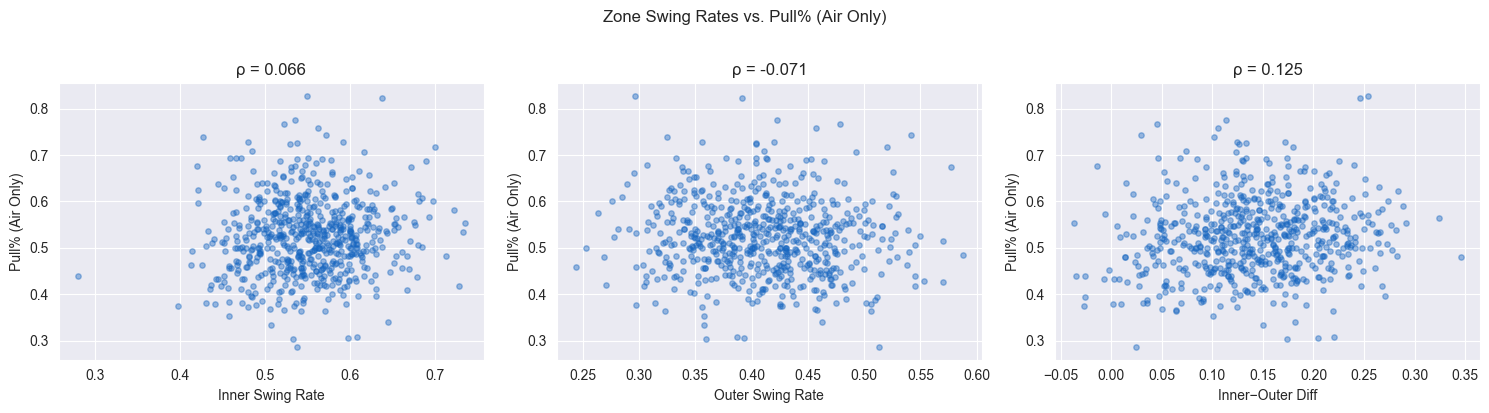

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, (label, col) in zip(axes, corr_feats.items()):
    paired = combined[["pull_air_only", col]].dropna()
    r_s, _ = spearmanr(paired["pull_air_only"], paired[col])
    ax.scatter(paired[col], paired["pull_air_only"],
               alpha=0.4, s=15, color="#1565C0")
    ax.set_xlabel(label)
    ax.set_ylabel("Pull% (Air Only)")
    ax.set_title(f"ρ = {r_s:.3f}")

plt.suptitle("Zone Swing Rates vs. Pull% (Air Only)", y=1.02, fontsize=12)
plt.tight_layout()
plt.show()


## 6. Stickiness of Zone Swing Rates

In [10]:
sr_cols = {
    "Inner Swing Rate":  "swing_rate_inner",
    "Outer Swing Rate":  "swing_rate_outer",
    "Inner−Outer Diff":  "inner_outer_diff",
    "Pull% (Air Only)":  None,   # handled separately
}

print(f"{'min_pitches':>12}  {'n_paired':>10}  "
      f"{'Inner SR':>10}  {'Outer SR':>10}  {'I-O Diff':>10}  {'Pull Air%':>10}")

stick_results = {col: [] for col in ["swing_rate_inner", "swing_rate_outer",
                                      "inner_outer_diff", "pull_air_only"]}

for min_p in range(25, 405, 25):
    sr24 = compute_swing_rates(pitches_2024, min_p)
    sr25 = compute_swing_rates(pitches_2025, min_p)
    pa24 = compute_pull_air_only(pitches_2024, max(10, min_p // 3))
    pa25 = compute_pull_air_only(pitches_2025, max(10, min_p // 3))

    rhos = {}
    for col in ["swing_rate_inner", "swing_rate_outer", "inner_outer_diff"]:
        paired = (
            sr24[["batter", col]].set_index("batter")[col].rename("y2024")
            .to_frame()
            .join(sr25[["batter", col]].set_index("batter")[col].rename("y2025"),
                  how="inner")
        )
        if len(paired) < 20:
            rhos[col] = np.nan
        else:
            rho, _ = spearmanr(paired["y2024"], paired["y2025"])
            rhos[col] = float(np.asarray(rho).flat[0])
            stick_results[col].append({"min_p": min_p, "n": len(paired), "rho": rhos[col]})

    # Pull% air only stickiness
    paired_pa = (
        pa24[["batter", "pull_air_only"]].set_index("batter")["pull_air_only"].rename("y2024")
        .to_frame()
        .join(pa25[["batter", "pull_air_only"]].set_index("batter")["pull_air_only"].rename("y2025"),
              how="inner")
    )
    if len(paired_pa) >= 20:
        rho_pa, _ = spearmanr(paired_pa["y2024"], paired_pa["y2025"])
        rho_pa = float(np.asarray(rho_pa).flat[0])
        stick_results["pull_air_only"].append({"min_p": min_p, "n": len(paired_pa), "rho": rho_pa})
    else:
        rho_pa = np.nan

    n = len(sr24.merge(sr25, on="batter", how="inner"))
    print(f"{min_p:>12}  {n:>10}  "
          f"{rhos.get('swing_rate_inner', np.nan):>10.4f}  "
          f"{rhos.get('swing_rate_outer', np.nan):>10.4f}  "
          f"{rhos.get('inner_outer_diff', np.nan):>10.4f}  "
          f"{rho_pa:>10.4f}")


 min_pitches    n_paired    Inner SR    Outer SR    I-O Diff   Pull Air%
          25         526      0.6517      0.6112      0.5397      0.5027
          50         502      0.6776      0.6518      0.5811      0.5569
          75         485      0.6988      0.6729      0.6082      0.5778
         100         467      0.7132      0.6841      0.6250      0.5873
         125         447      0.7279      0.6928      0.6217      0.5989
         150         438      0.7310      0.7048      0.6355      0.6238
         175         428      0.7273      0.7122      0.6359      0.6201
         200         412      0.7257      0.7233      0.6322      0.6319
         225         405      0.7272      0.7263      0.6356      0.6334
         250         401      0.7280      0.7319      0.6382      0.6439
         275         393      0.7324      0.7428      0.6534      0.6306
         300         389      0.7332      0.7441      0.6561      0.6488
         325         381      0.7422      0.7405   

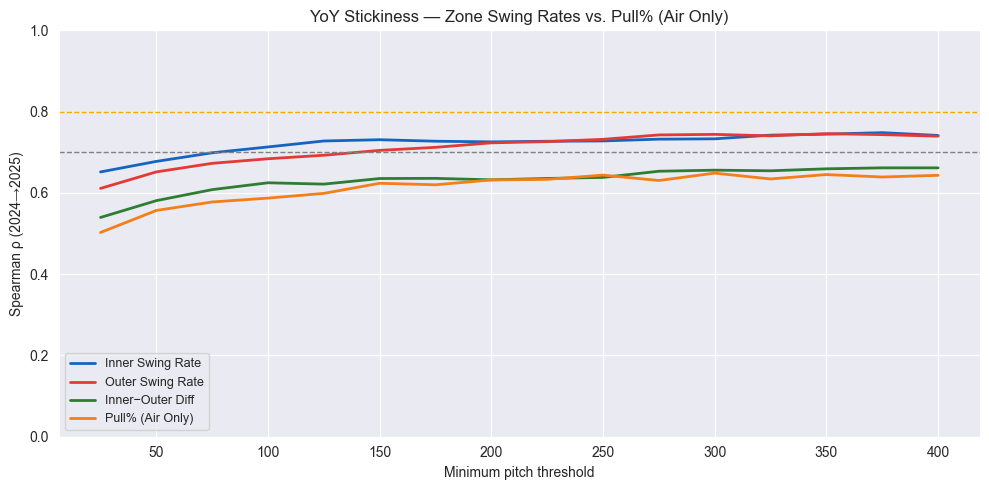

In [11]:
fig, ax = plt.subplots(figsize=(10, 5))

plot_cols = {
    "swing_rate_inner": ("#1565C0", "Inner Swing Rate"),
    "swing_rate_outer": ("#E53935", "Outer Swing Rate"),
    "inner_outer_diff": ("#2E7D32", "Inner−Outer Diff"),
    "pull_air_only":    ("#F57F17", "Pull% (Air Only)"),
}

for col, (color, label) in plot_cols.items():
    if not stick_results[col]:
        continue
    df_s = pd.DataFrame(stick_results[col])
    ax.plot(df_s["min_p"], df_s["rho"], color=color, linewidth=2, label=label)

ax.axhline(0.70, color="gray",   linewidth=1, linestyle="--")
ax.axhline(0.80, color="orange", linewidth=1, linestyle="--")
ax.set_xlabel("Minimum pitch threshold")
ax.set_ylabel("Spearman ρ (2024→2025)")
ax.set_title("YoY Stickiness — Zone Swing Rates vs. Pull% (Air Only)")
ax.legend(fontsize=9)
ax.set_ylim(0, 1)
plt.tight_layout()
plt.show()


## 7. Regression: Zone Swing Rates + Swing Metrics → Pull% (Air Only)

In [14]:
print(f"reg_df shape: {reg_df.shape}")
print(f"Non-null counts:")
print(reg_df[pred_cols + ["pull_air_only"]].notna().sum())

reg_df shape: (624, 17)
Non-null counts:
swing_rate_inner    624
swing_rate_outer    624
inner_outer_diff    624
mean_tilt           624
mean_aa             624
mean_dir              1
mean_depth          624
pull_air_only       624
dtype: int64


In [19]:
# Load swing metrics from batter_agg if available, otherwise compute from raw
swing_metric_cols = ["mean_tilt", "mean_aa", "mean_dir", "mean_depth"]

# Recompute batter-level swing metrics from combined pitches
contact_only = pitches_all[pitches_all["launch_speed"].notna()].copy()
contact_only["attack_direction_norm"] = np.where(
    contact_only["stand"] == "R",
    contact_only["attack_direction"],
    -contact_only["attack_direction"],
)

swing_agg = (
    contact_only.groupby("batter")
    .agg(
        mean_tilt  = ("swing_path_tilt",                          "mean"),
        mean_aa    = ("attack_angle",                              "mean"),
        mean_dir   = ("attack_direction_norm",                     "mean"),
        mean_depth = ("intercept_ball_minus_batter_pos_y_inches",  "mean"),
    )
    .reset_index()
)

print(f"swing_agg shape: {swing_agg.shape}")
print(swing_agg[["mean_tilt","mean_aa","mean_dir","mean_depth"]].notna().mean().round(3))

# Join everything
reg_df = (
    combined
    .merge(swing_agg, on="batter", how="left")
)

ALL_PREDICTORS = {
    "Tilt":       "mean_tilt",
    "Att Angle":  "mean_aa",
    "Att Dir":    "mean_dir",
    "Depth":      "mean_depth",
}

pred_cols = list(ALL_PREDICTORS.values())
sub = reg_df[pred_cols + ["pull_air_only"]].dropna()
X   = sub[pred_cols].values
y   = sub["pull_air_only"].values

pipe = Pipeline([
    ("scaler", StandardScaler()),
    ("ridge",  RidgeCV(alphas=[0.01, 0.1, 1, 10, 100], cv=5)),
])
pipe.fit(X, y)
cv_r2 = cross_val_score(pipe, X, y, cv=5, scoring="r2").mean()

coefs = pipe.named_steps["ridge"].coef_
print(f"Pull% (Air Only) — CV R² = {cv_r2:.4f}")
print(f"\n{'Feature':<15}  {'Std Coef':>10}")
print("-" * 28)
for label, coef in zip(ALL_PREDICTORS.keys(), coefs):
    print(f"{label:<15}  {coef:>10.4f}")


swing_agg shape: (1325, 5)
mean_tilt    0.665
mean_aa      0.665
mean_dir     0.665
mean_depth   0.665
dtype: float64
Pull% (Air Only) — CV R² = 0.3016

Feature            Std Coef
----------------------------
Tilt                 0.0162
Att Angle           -0.0351
Att Dir              0.0123
Depth               -0.0182


In [21]:
# Are covered batters different from uncovered?
has_metrics = reg_df["mean_tilt"].notna()
print("Pull% (Air Only) — with vs without swing metrics:")
print(f"  Has metrics  : {reg_df.loc[has_metrics,  'pull_air_only'].mean():.3f}  n={has_metrics.sum()}")
print(f"  No metrics   : {reg_df.loc[~has_metrics, 'pull_air_only'].mean():.3f}  n={(~has_metrics).sum()}")

Pull% (Air Only) — with vs without swing metrics:
  Has metrics  : 0.524  n=624
  No metrics   : nan  n=0


KeyError: 'swing_rate_inner'

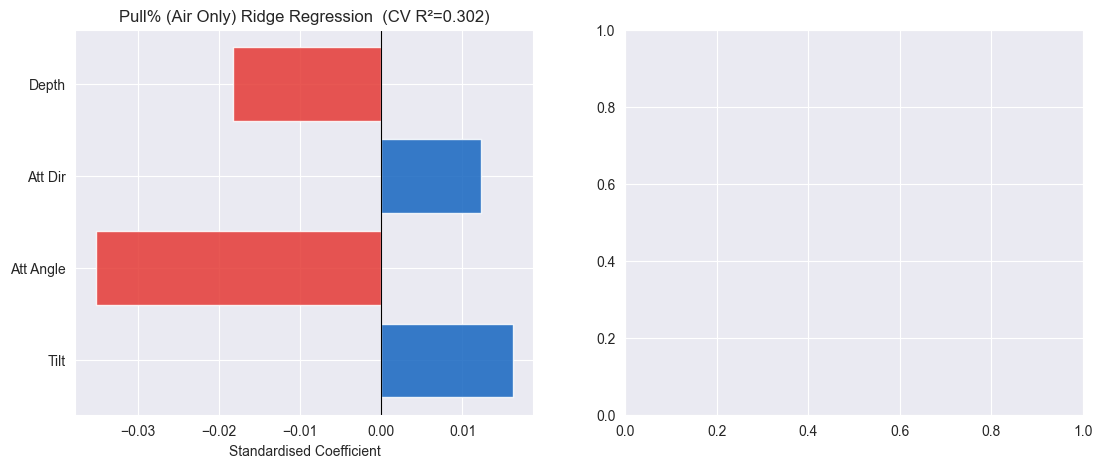

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Coefficient bar chart
colors = ["#1565C0" if c > 0 else "#E53935" for c in coefs]
axes[0].barh(list(ALL_PREDICTORS.keys()), coefs, color=colors, alpha=0.85)
axes[0].axvline(0, color="black", linewidth=0.8)
axes[0].set_xlabel("Standardised Coefficient")
axes[0].set_title(f"Pull% (Air Only) Ridge Regression  (CV R²={cv_r2:.3f})")

# Partial effects for zone swing rates
for col, color, label in [
    ("swing_rate_inner", "#1565C0", "Inner Swing Rate"),
    ("swing_rate_outer", "#E53935", "Outer Swing Rate"),
    ("inner_outer_diff", "#2E7D32", "Inner−Outer Diff"),
]:
    x_vals = sub[col].values
    grid   = np.linspace(x_vals.min(), x_vals.max(), 100)
    means  = sub[pred_cols].mean().values

    X_vary = np.tile(means, (100, 1))
    X_vary[:, pred_cols.index(col)] = grid

    X_vary_scaled = pipe.named_steps["scaler"].transform(X_vary)
    y_pred        = pipe.named_steps["ridge"].predict(X_vary_scaled)

    axes[1].plot(grid, y_pred, color=color, linewidth=2, label=label)

axes[1].set_xlabel("Swing Rate")
axes[1].set_ylabel("Predicted Pull% (Air Only)")
axes[1].set_title("Partial Effects — Zone Swing Rates")
axes[1].legend(fontsize=9)

plt.tight_layout()
plt.show()
